# Évaluation des métriques GNN — Projet AML

Ce notebook charge les métriques sauvegardées après l'entraînement (`data/results/gnn_*_metrics.json`)
et produit des **graphiques** pour la soutenance :

- tableau récapitulatif des métriques
- barres comparatives par modèle (HeteroGNN, GraphSAGE, GAT)
- courbes d'entraînement (loss / PR-AUC) si `*_history.json` existe
- courbe Precision-Recall sur le jeu **TEST**
- matrice de confusion et distribution des scores

> **Prérequis** : avoir lancé `python scripts/05_train_gnn.py` au moins une fois.
> Pour les courbes d'entraînement par epoch, relancer l'entraînement après mise à jour du code (historique sauvegardé automatiquement).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd


def find_project_root() -> Path:
    """Remonte les dossiers jusqu'à trouver src/config.py (robuste Jupyter)."""
    markers = ("src", "data", "scripts")
    candidates = [Path.cwd().resolve()]
    # Si le notebook est dans notebooks/, partir aussi de ce dossier
    nb_path = Path("metrics_evaluation.ipynb")
    if nb_path.exists():
        candidates.insert(0, nb_path.resolve().parent)
    elif (Path.cwd() / "notebooks" / "metrics_evaluation.ipynb").exists():
        candidates.insert(0, (Path.cwd() / "notebooks").resolve())

    for start in candidates:
        path = start
        for _ in range(8):
            if (path / "src" / "config.py").exists() and all((path / m).exists() for m in markers):
                return path
            if path.parent == path:
                break
            path = path.parent
    raise FileNotFoundError(
        "Racine du projet introuvable. Ouvrez le notebook depuis le dossier "
        "'Project' ou définissez le répertoire de travail sur la racine du projet."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.evaluation.metrics_viz import (
    discover_metrics_files,
    history_path_for_model,
    load_training_history,
    metrics_to_dataframe,
    plot_all_metrics_grid,
    plot_confusion_matrix,
    plot_metrics_bars,
    plot_precision_recall_curve,
    plot_score_distribution,
    plot_splits_comparison,
    plot_training_history,
    predict_hetero,
    predict_homo,
    set_plot_style,
)

set_plot_style()
RESULTS_DIR = config.RESULTS_DIR
print(f"Projet : {PROJECT_ROOT}")
print(f"Résultats : {RESULTS_DIR}")

Projet : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project
Résultats : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project\data\results


## 1. Chargement des métriques JSON

In [4]:
metrics_files = discover_metrics_files(RESULTS_DIR)
print("Fichiers trouvés :")
for p in metrics_files:
    print(f"  - {p.name}")

if not metrics_files:
    raise FileNotFoundError(
        f"Aucun gnn_*_metrics.json dans {RESULTS_DIR}. Lancez d'abord scripts/05_train_gnn.py"
    )

df_metrics = metrics_to_dataframe(metrics_files)
display_cols = ["model", "split_label", "pr_auc", "recall", "precision", "f1", "loss", "n_fraud", "best_epoch"]
df_metrics[display_cols].sort_values(["model", "split"])

Fichiers trouvés :
  - gnn_gat_metrics.json
  - gnn_hetero_metrics.json
  - gnn_sage_metrics.json


KeyError: 'split'

## 2. Comparaison des modèles — jeu TEST

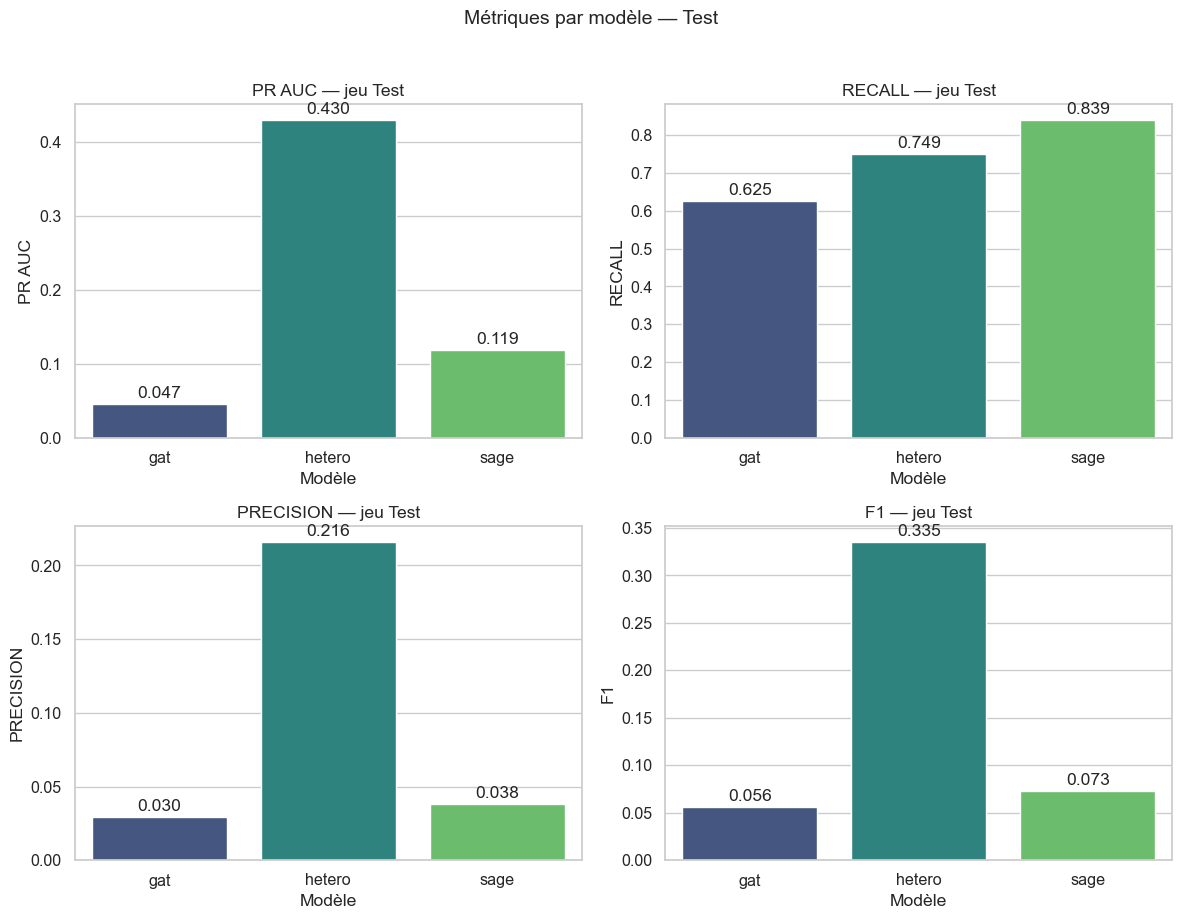

In [5]:
fig = plot_all_metrics_grid(df_metrics, split="test")
plt.show()

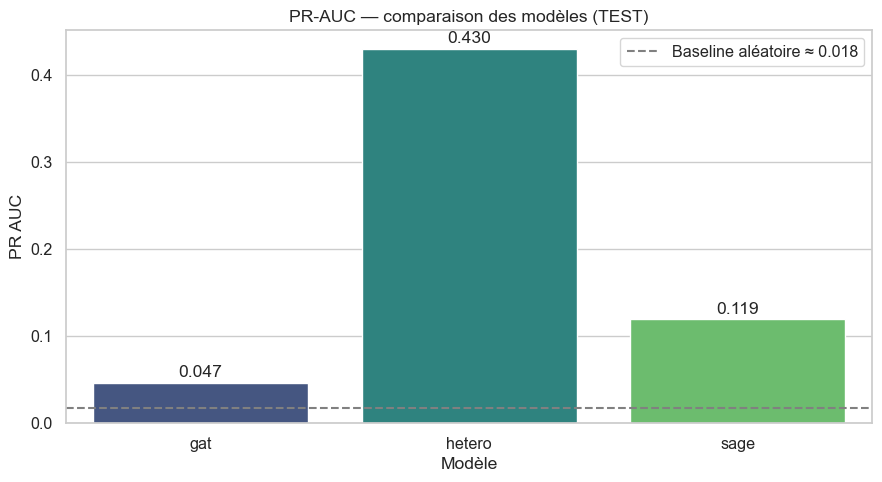

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_metrics_bars(df_metrics, metric="pr_auc", split="test", ax=ax,
                  title="PR-AUC — comparaison des modèles (TEST)")
baseline = df_metrics[(df_metrics["split"] == "test")]["n_fraud"].iloc[0] / df_metrics[
    (df_metrics["split"] == "test")
]["n_samples"].iloc[0]
ax.axhline(baseline, color="gray", linestyle="--", label=f"Baseline aléatoire ≈ {baseline:.3f}")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Métriques par split — modèle principal (HeteroGNN)

C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project\src\metrics_viz.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=s, x="split_label", y=metric, ax=ax, palette="muted")
C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project\src\metrics_viz.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=s, x="split_label", y=metric, ax=ax, palette="muted")
C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project\src\metrics_viz.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=s, x="split_label",

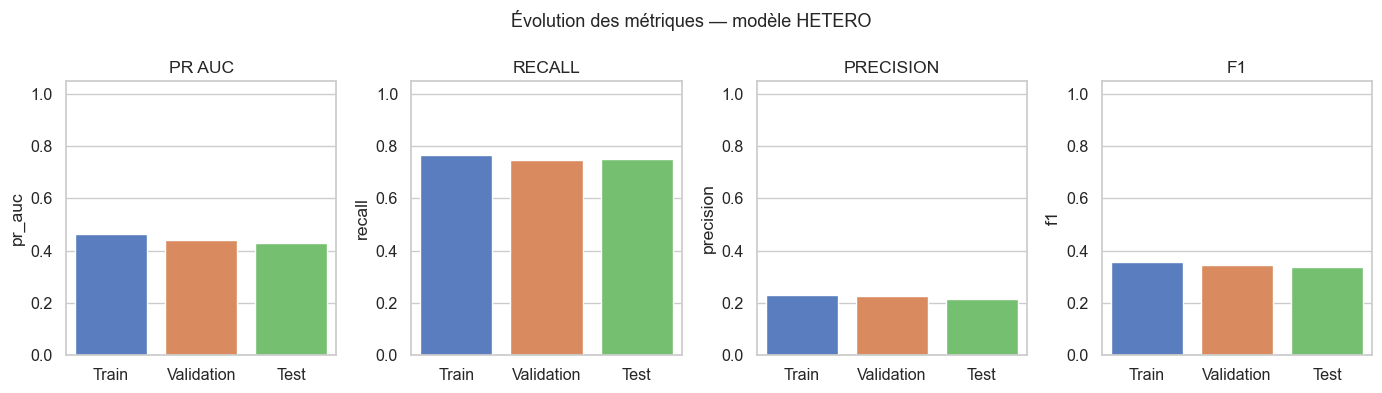

In [7]:
primary_model = "hetero" if "hetero" in df_metrics["model"].values else df_metrics["model"].iloc[0]
if primary_model in df_metrics["model"].values:
    fig = plot_splits_comparison(df_metrics, model=primary_model)
    plt.show()
else:
    print(f"Modèle {primary_model} absent du DataFrame.")

## 4. Courbes d'entraînement (loss & PR-AUC validation)

Disponible si `gnn_<model>_history.json` existe (généré lors du prochain entraînement).

[gat] Pas d'historique : gnn_gat_history.json — relancez 05_train_gnn.py


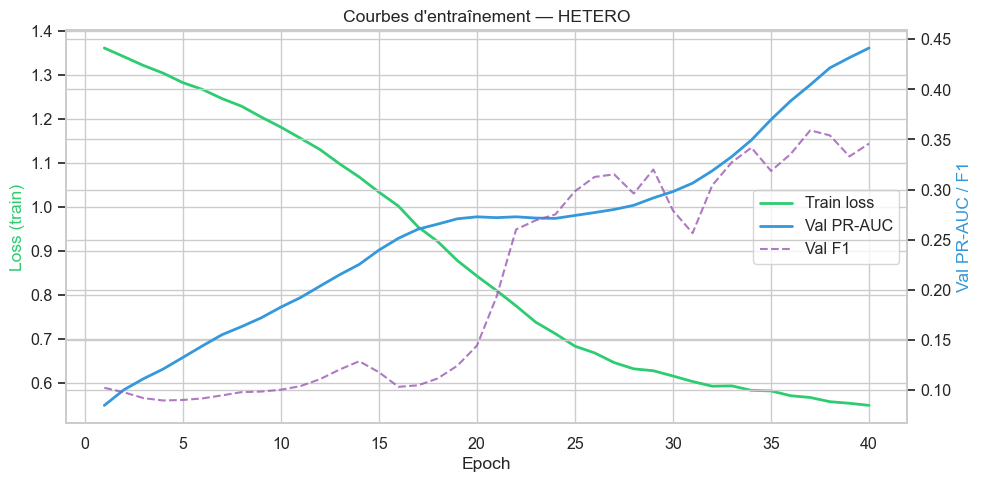

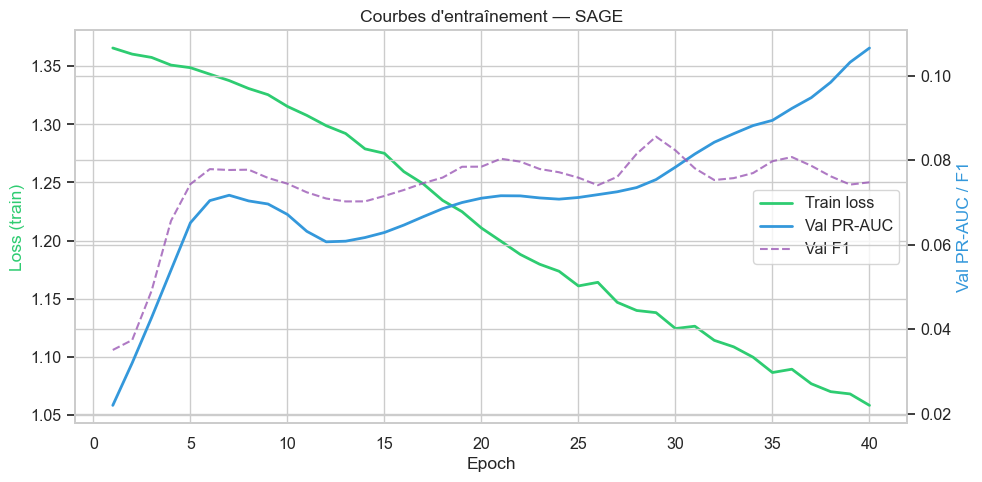

In [8]:
for model in df_metrics["model"].unique():
    hist_path = history_path_for_model(model)
    hist_df = load_training_history(hist_path)
    if hist_df is None or hist_df.empty:
        print(f"[{model}] Pas d'historique : {hist_path.name} — relancez 05_train_gnn.py")
        continue
    fig = plot_training_history(hist_df, model=model)
    plt.show()

## 5. Courbe Precision-Recall & matrice de confusion (jeu TEST)

Recalcule les scores à partir du checkpoint pour tracer les courbes détaillées.

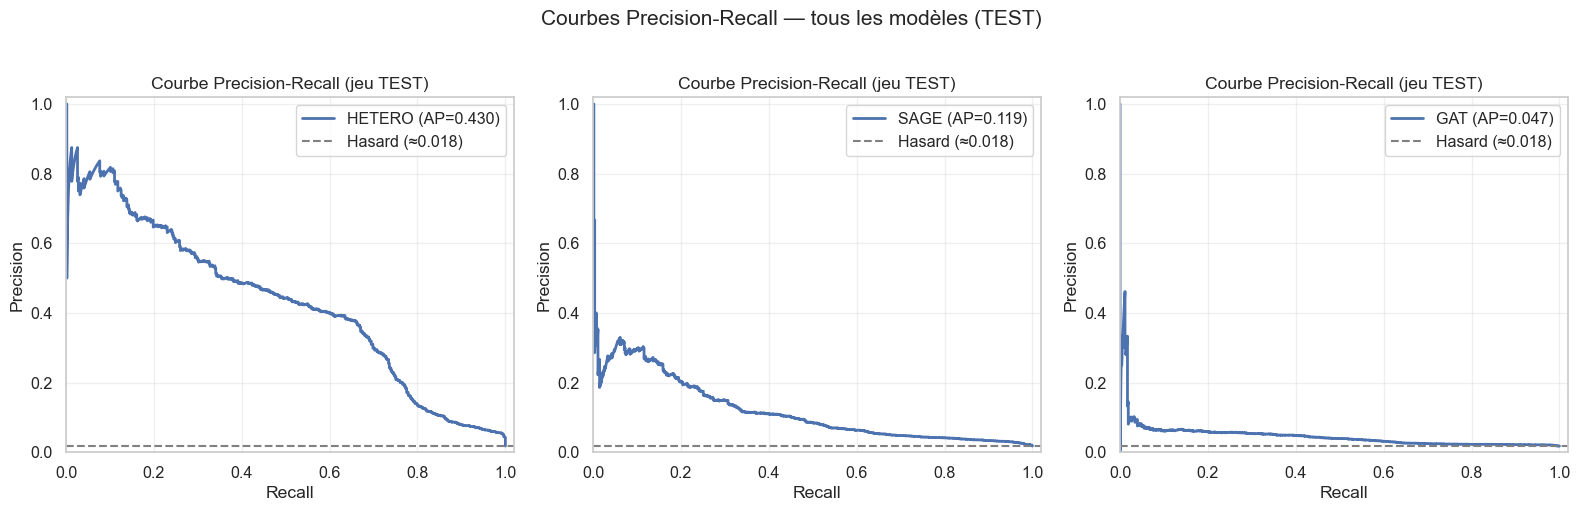

In [9]:
CHECKPOINTS = {
    "hetero": RESULTS_DIR / "gnn_hetero_best.pt",
    "sage": RESULTS_DIR / "gnn_sage_best.pt",
    "gat": RESULTS_DIR / "gnn_gat_best.pt",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, ckpt) in zip(axes, [(k, v) for k, v in CHECKPOINTS.items() if v.exists()]):
    if name == "hetero":
        y, probs, mask = predict_hetero(ckpt)
    else:
        y, probs, mask = predict_homo(ckpt)
    y_test, p_test = y[mask], probs[mask]
    baseline = y_test.mean()
    plot_precision_recall_curve(y_test, p_test, ax=ax, label=name.upper(), baseline_rate=baseline)

for ax in axes[len([c for c in CHECKPOINTS.values() if c.exists()]):]:
    ax.set_visible(False)

fig.suptitle("Courbes Precision-Recall — tous les modèles (TEST)", y=1.02)
plt.tight_layout()
plt.show()

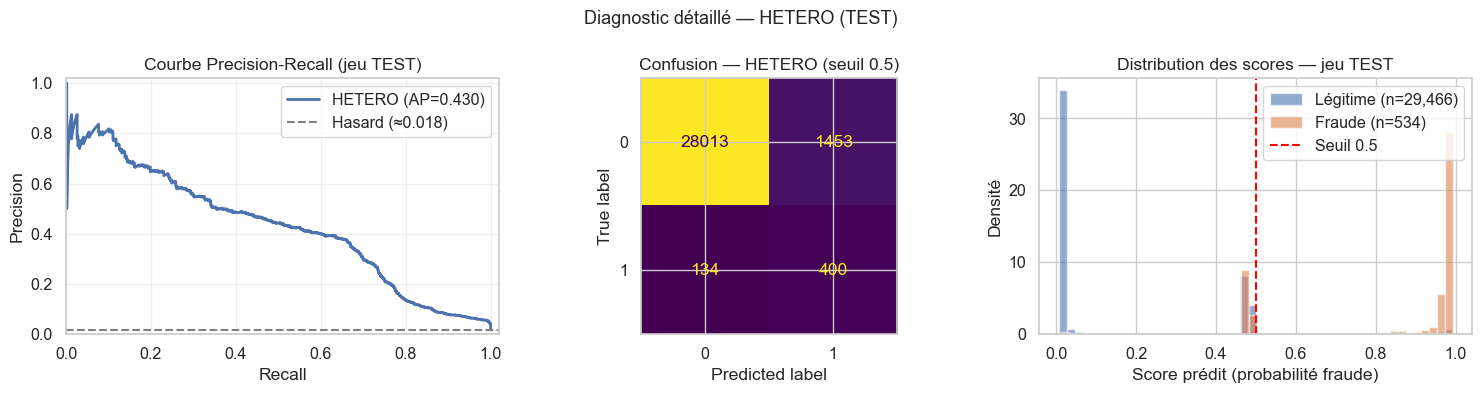

              precision    recall  f1-score   support

    Légitime       1.00      0.95      0.97     29466
      Fraude       0.22      0.75      0.34       534

    accuracy                           0.95     30000
   macro avg       0.61      0.85      0.65     30000
weighted avg       0.98      0.95      0.96     30000



In [10]:
ckpt_primary = CHECKPOINTS.get(primary_model)
if ckpt_primary is None or not ckpt_primary.exists():
    raise FileNotFoundError(f"Checkpoint introuvable pour {primary_model}")

if primary_model == "hetero":
    y, probs, mask = predict_hetero(ckpt_primary)
else:
    y, probs, mask = predict_homo(ckpt_primary)

y_test, p_test = y[mask], probs[mask]
baseline = float(y_test.mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_precision_recall_curve(y_test, p_test, ax=axes[0], label=primary_model.upper(), baseline_rate=baseline)
plot_confusion_matrix(y_test, p_test, ax=axes[1], title=f"Confusion — {primary_model.upper()} (seuil 0.5)")
plot_score_distribution(y_test, p_test, ax=axes[2])
fig.suptitle(f"Diagnostic détaillé — {primary_model.upper()} (TEST)", fontsize=13)
plt.tight_layout()
plt.show()

from sklearn.metrics import classification_report
print(classification_report(y_test, (p_test >= 0.5).astype(int), target_names=["Légitime", "Fraude"]))

## 7. Comparaison des architectures — Homogène vs Hétérogène multi-relationnel

**Comparaison valide** si les deux modèles ont été entraînés sur le **même sous-graphe** (200k transactions, 3 565 fraudes) avec le **même seed** (`RANDOM_SEED=42`) pour les splits train/val/test.

| Architecture | Graphe | Modèle | Source données |
|---|---|---|---|
| **GraphSAGE / GAT** | Homogène (`aml_graph.pt`) | Toutes arêtes traitées pareil | RDF ou CSV |
| **HeteroGNN** | Hétérogène (`aml_hetero_graph.pt`) | Poids distincts par prédicat RDF | RDF enrichi (inférence) |

```powershell
# Entraîner les deux pour comparer
python scripts/04_build_pyg.py --mode homo && python scripts/05_train_gnn.py --model sage
python scripts/04_build_pyg.py --mode hetero && python scripts/05_train_gnn.py --model hetero
```

In [ ]:
from src.evaluation.metrics_viz import (
    architecture_comparison_table,
    plot_architecture_comparison,
    plot_architecture_radar,
    plot_training_history_comparison,
)

# Tableau avec écarts HeteroGNN − GraphSAGE
if {"hetero", "sage"}.issubset(set(df_metrics["model"])):
    cmp_table = architecture_comparison_table(df_metrics, split="test")
    display(cmp_table.style.format({c: "{:.4f}" for c in cmp_table.columns if c != "métrique"}))
else:
    print("Entraînez sage et hetero pour le tableau comparatif.")

fig = plot_architecture_comparison(df_metrics, split="test")
plt.show()

fig = plot_architecture_radar(df_metrics, split="test")
plt.show()

fig = plot_training_history_comparison(["hetero", "sage", "gat"])
if fig:
    plt.show()
else:
    print("Historiques d'entraînement absents — relancez 05_train_gnn.py pour chaque modèle.")

## 9. Étude de convergence (GraphSAGE vs HeteroGNN)

Analyse **epoch par epoch** (courbes alignées, sans early stopping). Générer les historiques avec :

```powershell
python scripts/06_compare_convergence.py --epochs 40 --retrain
```

In [13]:
from src.evaluation.convergence_compare import (
    merge_convergence_histories,
    plot_convergence_comparison,
    plot_convergence_gaps,
    analyze_divergence,
)
from src.evaluation.metrics_viz import load_training_history
from src import config

sage_path = config.RESULTS_DIR / "gnn_sage_history.json"
hetero_path = config.RESULTS_DIR / "gnn_hetero_history.json"

sage = load_training_history(sage_path)
hetero = load_training_history(hetero_path)

if sage is None or hetero is None:
    print("Historiques manquants. Lancez :")
    print("  python scripts/06_compare_convergence.py --epochs 40 --retrain")
else:
    merged = merge_convergence_histories(sage, hetero)
    display(merged[["epoch", "sage_val_pr_auc", "hetero_val_pr_auc", "gap_val_pr_auc"]].head(10))
    display(merged[["epoch", "sage_val_pr_auc", "hetero_val_pr_auc", "gap_val_pr_auc"]].tail(5))
    print("Analyse :", analyze_divergence(merged))
    plot_convergence_comparison(merged)
    plt.show()
    plot_convergence_gaps(merged)
    plt.show()

,epoch,sage_val_pr_auc,hetero_val_pr_auc,gap_val_pr_auc
0,1,0.021996,0.084628,0.062632
1,2,0.032034,0.100192,0.068158
2,3,0.042772,0.111245,0.068472
3,4,0.053997,0.120876,0.066879
4,5,0.065189,0.132369,0.067180
5,6,0.070443,0.143948,0.073505
6,7,0.071714,0.155116,0.083402
7,8,0.070373,0.163231,0.092858
8,9,0.069643,0.171982,0.102339
9,10,0.067171,0.182619,0.115447


,epoch,sage_val_pr_auc,hetero_val_pr_auc,gap_val_pr_auc
35,36,0.092261,0.388426,0.296165
36,37,0.094805,0.404477,0.309672
37,38,0.098441,0.421409,0.322968
38,39,0.103181,0.431639,0.328457
39,40,0.106551,0.441240,0.334689


Analyse : {'first_epoch_gap_pr_auc_0.01': 1, 'first_epoch_gap_f1_0.01': 1, 'epoch_max_abs_gap_pr_auc': 40, 'max_abs_gap_pr_auc': 0.33468901028335757, 'gap_at_max_epoch': 0.33468901028335757, 'final_epoch': 40, 'final_gap_val_pr_auc': 0.33468901028335757, 'final_sage_val_pr_auc': 0.10655129619464238, 'final_hetero_val_pr_auc': 0.44124030647799994, 'final_gap_val_recall': -0.1084112149532711, 'first_epoch_hetero_ahead_pr_auc': 1, 'first_epoch_sage_ahead_pr_auc': None}


In [12]:
test_df = df_metrics[df_metrics["split"] == "test"].copy()
test_df["fraud_rate_%"] = (100 * test_df["n_fraud"] / test_df["n_samples"]).round(2)
baseline_rate = test_df["n_fraud"] / test_df["n_samples"]
test_df["pr_auc_vs_baseline"] = (test_df["pr_auc"] / baseline_rate).round(1)

summary = test_df[[
    "model", "pr_auc", "recall", "precision", "f1",
    "n_samples", "n_fraud", "fraud_rate_%", "best_epoch"
]].set_index("model")
display(summary.style.background_gradient(subset=["pr_auc", "recall", "f1"], cmap="YlGn"))

print("\nInterprétation rapide :")
print("- PR-AUC >> taux de fraude  => le modèle classe mieux que le hasard")
print("- Recall élevé           => peu de fraudes manquées (orienté détection AML)")
print("- Precision faible       => beaucoup de faux positifs ; ajuster le seuil en production")

,pr_auc,recall,precision,f1,n_samples,n_fraud,fraud_rate_%,best_epoch
model,,,,,,,,
gat,0.046680,0.625468,0.029529,0.056395,30000,534,1.780000,3
hetero,0.429733,0.749064,0.215866,0.335149,30000,534,1.780000,40
sage,0.119386,0.838951,0.038066,0.072828,30000,534,1.780000,40



Interprétation rapide :
- PR-AUC >> taux de fraude  => le modèle classe mieux que le hasard
- Recall élevé           => peu de fraudes manquées (orienté détection AML)
- Precision faible       => beaucoup de faux positifs ; ajuster le seuil en production
